# NYC Restaurant Inspections: Cleaning and Exploratory Analysis

**Data:** DOHMH New York City Restaurant Inspection Results (NYC Open Data, dataset `43nn-pn8j`), downloaded 2026-11-11.

**Questions**
1. How do inspection scores and grades differ across boroughs?
2. Which cuisines have the highest and lowest average inspection scores?
3. What are the most common violations, and how many are critical?
4. Have scores changed over time?
5. Do restaurants that score poorly improve on re-inspection?

**How to read the data:** one row is one *violation*, not one inspection. The inspection score repeats on every violation row of the same inspection. A **lower score is better** (A: 0-13, B: 14-27, C: 28+). Averaging the raw rows would overweight inspections with many violations, so the analysis below first builds a table with one row per inspection.

In [9]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

Path("images").mkdir(exist_ok=True)
Path("data/clean").mkdir(parents=True, exist_ok=True)

# Palette: validated categorical slots (blue, orange) plus neutral grey
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b5b4ae"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10,
})

def save(name):
    plt.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Load and inspect

In [19]:
CSV = "DOHMH_New_York_City_Restaurant_Inspection_Results_20261111.csv"
df = pd.read_csv(CSV, low_memory=False)
df_raw = df.copy()   # untouched copy to compare against

print(df.shape)
df.info()

(294700, 27)
<class 'pandas.DataFrame'>
RangeIndex: 294700 entries, 0 to 294699
Data columns (total 27 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   CAMIS                  294700 non-null  int64  
 1   DBA                    294697 non-null  str    
 2   BORO                   294700 non-null  str    
 3   BUILDING               293716 non-null  str    
 4   STREET                 294638 non-null  str    
 5   ZIPCODE                291584 non-null  float64
 6   PHONE                  294588 non-null  str    
 7   CUISINE DESCRIPTION    290596 non-null  str    
 8   INSPECTION DATE        294700 non-null  str    
 9   ACTION                 290676 non-null  str    
 10  VIOLATION CODE         287596 non-null  str    
 11  VIOLATION DESCRIPTION  287596 non-null  str    
 12  CRITICAL FLAG          294700 non-null  str    
 13  SCORE                  277227 non-null  float64
 14  GRADE                  144403 non-

In [20]:
display(df.isna().sum().sort_values(ascending=False).to_frame("missing").assign(pct=lambda d: d.missing / len(df) * 100).head(15))
print("Fully duplicated rows:", df.duplicated().sum())

,missing,pct
GRADE DATE,160562,54.48
GRADE,150297,51.00
SCORE,17473,5.93
VIOLATION DESCRIPTION,7104,2.41
VIOLATION CODE,7104,2.41
BIN,5821,1.98
Location,4680,1.59
NTA,4680,1.59
Community Board,4680,1.59
Census Tract,4666,1.58


Fully duplicated rows: 225


In [21]:
# Domain checks on the raw data (original column names)
for col in ["BORO", "GRADE", "CRITICAL FLAG", "ACTION", "INSPECTION DATE", "GRADE"]:
    print(df[col].value_counts(dropna=False).head(12), "\n")
print(df["INSPECTION DATE"].head(3).tolist(), "<- dates arrive as MM/DD/YYYY text")
print("Unique restaurants (CAMIS):", df["CAMIS"].nunique())

BORO
Manhattan        109123
Brooklyn          74400
Queens            74017
Bronx             27486
Staten Island      9376
0                   298
Name: count, dtype: int64 

GRADE
NaN    150297
A       97597
B       17827
C       12848
N       10277
Z        5163
P         691
Name: count, dtype: int64 

CRITICAL FLAG
Critical          154021
Not Critical      131784
Not Applicable      8895
Name: count, dtype: int64 

ACTION
Violations were cited in the following area(s).                                                                                       273860
Establishment Closed by DOHMH. Violations were cited in the following area(s) and those requiring immediate action were addressed.     10997
NaN                                                                                                                                     4024
No violations were recorded at the time of this inspection.                                                                             2962
Est

### Issues found (written before cleaning anything)
- Dates are text (`MM/DD/YYYY`), not datetimes.
- **4,024 rows have `INSPECTION DATE = 01/01/1900`**: a placeholder for restaurants that have not been inspected yet. Their score, grade, violation and inspection type are all empty.
- **225 fully duplicated rows.**
- 298 rows have borough `0`.
- ZIP codes are not only from New York City and there is one clear typo (`69361`).
- 3,052 rows have latitude/longitude of `0`.
- Extra spaces inside street names (`EAST   92 STREET`).
- `GRADE` mixes letter grades with status codes (`N`, `Z`, `P`) and is empty for `150297` rows.
- `SCORE` has few scores that are very high (max 214).
- `RECORD DATE` is a single constant value being repeated for each row. 
- `Location` is a concatenation of Longitude and Latitude.
- The file has one row per violation, so analysis for restaurants should be made on a different table.

## 2. Cleaning (with a log)

In [22]:
log = []
def note(problem, decision, reason, rows):
    log.append({"problem": problem, "decision": decision, "reason": reason, "rows_affected": rows})

# 2.1 Column names
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
note("Column names have spaces and mixed case", "Converted to snake_case", "Easier to reference, no hidden-whitespace bugs", df.shape[1])
df.columns.tolist()

['camis',
 'dba',
 'boro',
 'building',
 'street',
 'zipcode',
 'phone',
 'cuisine_description',
 'inspection_date',
 'action',
 'violation_code',
 'violation_description',
 'critical_flag',
 'score',
 'grade',
 'grade_date',
 'record_date',
 'inspection_type',
 'latitude',
 'longitude',
 'community_board',
 'council_district',
 'census_tract',
 'bin',
 'bbl',
 'nta',
 'location']

In [23]:
# 2.2 Dates: parse text -> datetime, then handle the 1900-01-01 placeholder
for col in ["inspection_date", "grade_date", "record_date"]:
    df[col] = pd.to_datetime(df[col], format="%m/%d/%Y", errors="coerce")
note("Dates stored as text (MM/DD/YYYY)", "Parsed with an explicit format", "Needed for sorting, time series and date arithmetic", 3)

# Flag must be created BEFORE the placeholder is replaced
df["never_inspected"] = df["inspection_date"] == "1900-01-01"
n_placeholder = int(df["never_inspected"].sum())

# Confirm these really are "not yet inspected" records
print("Non-empty values in placeholder rows:")
print(df.loc[df["never_inspected"], ["score", "grade", "violation_code", "inspection_type", "action"]].notna().sum())

df.loc[df["never_inspected"], "inspection_date"] = pd.NaT
note("inspection_date = 1900-01-01", "Set to NaT and flagged `never_inspected`",
     "Placeholder for restaurants not inspected yet (score, grade, violations all empty). Kept the rows so restaurant counts stay complete",
     n_placeholder)
print("\nPlaceholder rows:", n_placeholder)
print(df[["inspection_date", "grade_date", "record_date"]].agg(["min", "max"]))

Non-empty values in placeholder rows:
score              0
grade              0
violation_code     0
inspection_type    0
action             0
dtype: int64

Placeholder rows: 4024
    inspection_date grade_date record_date
min      2007-08-10 2011-08-10  2026-11-10
max      2026-11-09 2026-11-09  2026-11-10


In [24]:
# 2.3 Exact duplicates
dup_mask = df.duplicated(keep=False)
display(df[dup_mask].sort_values(["camis", "inspection_date", "violation_code"])[["camis", "dba", "inspection_date", "violation_code", "score"]].head(6))
n_dups = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
note("Fully duplicated rows", "Dropped, kept first copy", "Identical in all 27 columns, so they carry no extra information", n_dups)
print("Dropped:", n_dups, "| rows now:", len(df))

,camis,dba,inspection_date,violation_code,score
22304,40390409,THE FAMOUS JIMBO'S HAMBURGER PALACE,2026-02-10,02G,23.00
24625,40390409,THE FAMOUS JIMBO'S HAMBURGER PALACE,2026-02-10,02G,23.00
285540,40390409,THE FAMOUS JIMBO'S HAMBURGER PALACE,2026-02-10,06B,23.00
286924,40390409,THE FAMOUS JIMBO'S HAMBURGER PALACE,2026-02-10,06B,23.00
106265,40390409,THE FAMOUS JIMBO'S HAMBURGER PALACE,2026-02-10,09A,23.00
109116,40390409,THE FAMOUS JIMBO'S HAMBURGER PALACE,2026-02-10,09A,23.00


Dropped: 225 | rows now: 294475


In [25]:
# 2.4 Borough '0'
n_boro0 = int((df["boro"] == "0").sum())
print("Distinct restaurants with boro 0:", df.loc[df["boro"] == "0", "camis"].nunique())
df.loc[df["boro"] == "0", "boro"] = np.nan
note("boro = '0'", "Set to missing", "Not a real borough; excluded from borough comparisons only", n_boro0)

# 2.5 ZIP codes: keep only NYC range, store as 5-character text
z = df["zipcode"]
bad_zip = z.notna() & ~z.between(10000, 11697)
print("ZIPs outside NYC range, most common:", z[bad_zip].astype(int).value_counts().head(5).to_dict())
df.loc[bad_zip, "zipcode"] = np.nan
df["zipcode"] = df["zipcode"].astype("Int64").astype("string")
note("ZIP codes outside NYC (NJ, Long Island) or invalid (69361)", "Set to missing; stored as text", "ZIP is an identifier, not a number", int(bad_zip.sum()))

# 2.6 Coordinates of 0 / outside the NYC bounding box
bad_geo = df["latitude"].notna() & ~(df["latitude"].between(40.4, 41.0) & df["longitude"].between(-74.3, -73.6))
df.loc[bad_geo, ["latitude", "longitude"]] = np.nan
note("Latitude/longitude of 0 (outside NYC)", "Set to missing", "Would plot in the Atlantic Ocean", int(bad_geo.sum()))
print("Boro 0 rows:", n_boro0, "| bad ZIP rows:", int(bad_zip.sum()), "| bad coordinates:", int(bad_geo.sum()))

Distinct restaurants with boro 0: 103
ZIPs outside NYC range, most common: {7307: 37, 7071: 13, 7002: 12, 7631: 12, 8550: 12}
Boro 0 rows: 298 | bad ZIP rows: 129 | bad coordinates: 3046


In [26]:
# 2.7 Text: trim and collapse repeated spaces
text_cols = ["dba", "building", "street", "cuisine_description", "boro"]
changed = 0
for c in text_cols:
    before = df[c].astype("string")
    after = before.str.strip().str.replace(r"\s+", " ", regex=True)
    changed += int((before.fillna("") != after.fillna("")).sum())
    df[c] = after
note("Extra/repeated spaces in text fields (e.g. 'EAST   92 STREET')", "Trimmed and collapsed to single spaces", "Same street must not appear under two spellings", changed)

df = df.rename(columns={"cuisine_description": "cuisine"})
n_na_cuisine = int((df["cuisine"] == "Not Listed/Not Applicable").sum())
df.loc[df["cuisine"] == "Not Listed/Not Applicable", "cuisine"] = pd.NA
note("Cuisine 'Not Listed/Not Applicable'", "Set to missing", "It is a placeholder, not a cuisine", n_na_cuisine)
print("Text cells changed:", changed)

Text cells changed: 39386


In [27]:
# 2.8 Grades and scores
print("Raw grade counts:\n", df["grade"].value_counts(dropna=False), "\n")

# N = not yet graded, Z = grade pending, P = pending after reopening following a closure.
df["letter_grade"] = df["grade"].where(df["grade"].isin(["A", "B", "C"]))
note("GRADE mixes letters (A/B/C) with status codes (N, Z, P) and is empty for ~half the rows",
     "Kept raw `grade`; added `letter_grade` (A/B/C only). Analysis uses SCORE bands instead",
     "Grades are only issued for some inspection types; the numeric score exists for far more inspections",
     int(df["grade"].isin(["N", "Z", "P"]).sum() + df["grade"].isna().sum()))

df["score_band"] = pd.cut(df["score"], [-1, 13, 27, np.inf], labels=["A", "B", "C"])

# Do letter grades agree with score bands?
both = df["letter_grade"].notna() & df["score_band"].notna()
mismatch = both & (df["letter_grade"] != df["score_band"].astype("string"))
print(f"Letter grade vs score band disagree on {mismatch.sum():,} of {both.sum():,} graded rows ({mismatch.mean() / both.mean() * 100:.1f}%)")
display(pd.crosstab(df.loc[both, "letter_grade"], df.loc[both, "score_band"]))
print("Score range:", df["score"].min(), "to", df["score"].max(), "| negative scores:", int((df["score"] < 0).sum()))
print("Scores above 100:", int((df["score"] > 100).sum()), "rows (kept: very high scores are real, usually closures)")
note("Very high scores (max 214)", "Kept", "Plausible for establishments closed for serious violations; they are real observations", int((df["score"] > 100).sum()))

Raw grade counts:
 grade
NaN    150134
A       97597
B       17827
C       12848
N       10251
Z        5127
P         691
Name: count, dtype: int64 

Letter grade vs score band disagree on 417 of 128,268 graded rows (0.3%)


score_band,A,B,C
letter_grade,,,
A,97593,2,0
B,24,17729,74
C,295,22,12529


Score range: 0.0 to 214.0 | negative scores: 0
Scores above 100: 2056 rows (kept: very high scores are real, usually closures)


In [28]:
# 2.9 Why is violation_code empty?
miss = df["violation_code"].isna()
print(pd.crosstab(miss.rename("violation_code missing"), df["never_inspected"].rename("never_inspected")))
print("\nAction text where violation_code is missing and the restaurant WAS inspected:")
print(df.loc[miss & ~df["never_inspected"], "action"].value_counts(dropna=False))

never_inspected          False  True 
violation_code missing               
False                   287371      0
True                      3080   4024

Action text where violation_code is missing and the restaurant WAS inspected:
action
No violations were recorded at the time of this inspection.                                                                           2770
Establishment re-opened by DOHMH.                                                                                                      303
Violations were cited in the following area(s).                                                                                          4
Establishment Closed by DOHMH. Violations were cited in the following area(s) and those requiring immediate action were addressed.       2
Establishment re-closed by DOHMH.                                                                                                        1
Name: count, dtype: int64


In [29]:
# 2.10 Helper flags and columns to drop
df["is_critical"] = df["critical_flag"].eq("Critical")
df["is_closure"] = df["action"].fillna("").str.contains("closed by DOHMH", case=False)

drop_cols = ["record_date", "location", "phone"]
df = df.drop(columns=drop_cols)
note("record_date is one constant value; location duplicates lat/long; phone not needed", "Dropped", "No analytical value", len(drop_cols))

print(df.shape)
print("Missing violation_code on inspected rows = inspections with no violations recorded (kept as real data).")

(294475, 29)
Missing violation_code on inspected rows = inspections with no violations recorded (kept as real data).


## 3. Build the inspection-level table
One inspection = one restaurant (`camis`) + one date + one inspection type. Violation rows are collapsed to a single row per inspection so scores are not counted once per violation.

In [30]:
KEY = ["camis", "inspection_date", "inspection_type"]
v = df[~df["never_inspected"]].copy()
v["inspection_id"] = v.groupby(KEY).ngroup()

# Does each inspection have ONE score / grade / action?
chk = v.groupby("inspection_id").agg(n_score=("score", "nunique"), n_grade=("grade", "nunique"), n_action=("action", "nunique"))
print("Inspections with more than one distinct value:\n", (chk > 1).sum())

insp = v.groupby(KEY, as_index=False).agg(
    dba=("dba", "first"), boro=("boro", "first"), zipcode=("zipcode", "first"), cuisine=("cuisine", "first"),
    score=("score", "max"), grade=("grade", "first"), letter_grade=("letter_grade", "first"),
    n_violations=("violation_code", "count"), n_critical=("is_critical", "sum"), closed=("is_closure", "max"),
)
insp["score_band"] = pd.cut(insp["score"], [-1, 13, 27, np.inf], labels=["A", "B", "C"])

print(f"\n{len(v):,} violation rows -> {len(insp):,} inspections across {insp['camis'].nunique():,} restaurants")
print("Restaurants in the full file (incl. never inspected):", df["camis"].nunique())

# Missing scores by inspection type
ms = insp.groupby("inspection_type")["score"].agg(inspections="size", missing=lambda s: s.isna().sum())
ms["pct_missing"] = ms["missing"] / ms["inspections"] * 100
display(ms.sort_values("inspections", ascending=False).head(8))

Inspections with more than one distinct value:
 n_score     0
n_grade     0
n_action    0
dtype: int64

290,451 violation rows -> 92,741 inspections across 27,446 restaurants
Restaurants in the full file (incl. never inspected): 31470


,inspections,missing,pct_missing
inspection_type,,,
Cycle Inspection / Initial Inspection,46793,0,0.00
Cycle Inspection / Re-inspection,17144,0,0.00
Pre-permit (Operational) / Initial Inspection,10195,0,0.00
Administrative Miscellaneous / Initial Inspection,7293,7293,100.00
Pre-permit (Operational) / Re-inspection,3032,0,0.00
Administrative Miscellaneous / Re-inspection,1306,1306,100.00
Inter-Agency Task Force / Initial Inspection,1276,0,0.00
Cycle Inspection / Reopening Inspection,1261,0,0.00


### Coverage check: which years can we trust?
Before comparing anything over time, check how many inspections exist per year.

inspection_date,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
inspections,12,6,1,4,2,5,1,5,5,73,125,156,188,49,64,2023,12292,24281,26991,26458


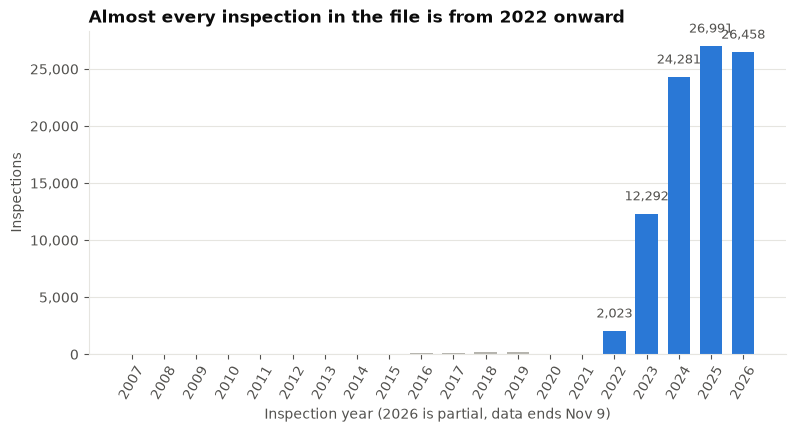

In [31]:
by_year = insp.groupby(insp["inspection_date"].dt.year).size()
display(by_year.to_frame("inspections").T)

fig, ax = plt.subplots(figsize=(9, 4.2))
colors = [BLUE if y >= 2022 else GRAY for y in by_year.index]
ax.bar(by_year.index.astype(str), by_year.values, color=colors, width=0.7)
for y, n in by_year.items():
    if y >= 2022:
        ax.text(str(y), n + 1200, f"{n:,}", ha="center", fontsize=9, color=INK2)
ax.set_title("Almost every inspection in the file is from 2022 onward")
ax.set_ylabel("Inspections"); ax.set_xlabel("Inspection year (2026 is partial, data ends Nov 9)")
ax.tick_params(axis="x", rotation=60); ax.grid(axis="x", visible=False)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
save("01_inspections_per_year")

Earlier years hold only a few hundred inspections each, so they are not a representative history. **All analyses below use inspections from 2022 onward.** The cycle inspections (the routine, graded visits) are the comparable unit: `Cycle Inspection / Initial Inspection`.

Inspections since 2022: 92,045 | graded-style initial cycle inspections with a score: 46,408


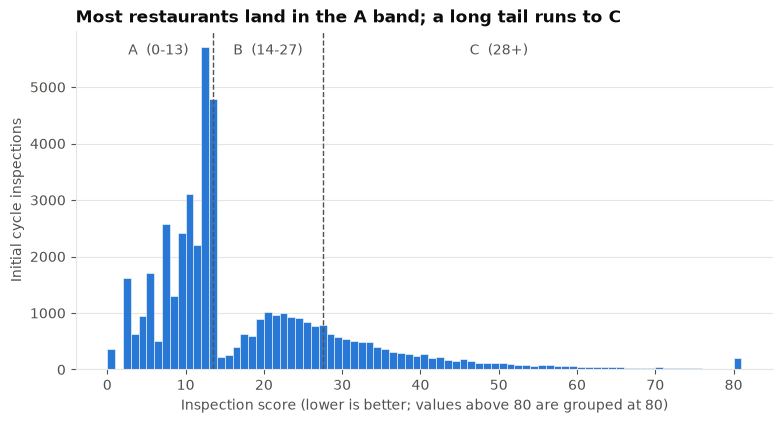

Median 13 | mean 17.6 | A 60.1% | B 22.0% | C 18.0% | above 80: 198


In [32]:
INIT = "Cycle Inspection / Initial Inspection"
REINSP = "Cycle Inspection / Re-inspection"

recent = insp[insp["inspection_date"] >= "2022-01-01"].copy()
cyc_init = recent[(recent["inspection_type"] == INIT) & recent["score"].notna()].copy()
print(f"Inspections since 2022: {len(recent):,} | graded-style initial cycle inspections with a score: {len(cyc_init):,}")

# Score distribution
fig, ax = plt.subplots(figsize=(9, 4.4))
s = cyc_init["score"]
ax.hist(s.clip(upper=80), bins=np.arange(0, 82, 1), color=BLUE, edgecolor="white", linewidth=0.4)
for x in (13.5, 27.5):
    ax.axvline(x, color=INK2, linestyle="--", linewidth=1)
ymax = ax.get_ylim()[1]
for x, t in [(6.5, "A  (0-13)"), (20.5, "B  (14-27)"), (50, "C  (28+)")]:
    ax.text(x, ymax * 0.93, t, ha="center", fontsize=10, color=INK2)
ax.set_title("Most restaurants land in the A band; a long tail runs to C")
ax.set_xlabel("Inspection score (lower is better; values above 80 are grouped at 80)"); ax.set_ylabel("Initial cycle inspections")
ax.grid(axis="x", visible=False)
save("02_score_distribution")
print(f"Median {s.median():.0f} | mean {s.mean():.1f} | A {np.mean(s<=13)*100:.1f}% | B {np.mean((s>13)&(s<=27))*100:.1f}% | C {np.mean(s>=28)*100:.1f}% | above 80: {(s>80).sum():,}")

## 4. Q1: Scores and grades by borough
Uses initial cycle inspections since 2022 (the like-for-like comparison).

In [35]:
r = recent.groupby("boro").agg(restaurants=("camis", "nunique"), all_inspections=("camis", "size"), closure_rate_pct=("closed", lambda s: s.mean() * 100))
c = cyc_init.groupby("boro")["score"].agg(
    initial_inspections="size", mean_score="mean", median_score="median",
    pct_A=lambda s: (s <= 13).mean() * 100, pct_C=lambda s: (s >= 28).mean() * 100)
boro_tbl = r.join(c).sort_values("mean_score")
display(boro_tbl)

from scipy import stats
groups = [g["score"].values for _, g in cyc_init.dropna(subset=["boro"]).groupby("boro")]
h, p = stats.kruskal(*groups)
print(f"Kruskal-Wallis across boroughs: H = {h:.1f}, p = {p:.2g}")
spread = boro_tbl["mean_score"].max() - boro_tbl["mean_score"].min()
print(f"Gap between best and worst borough in mean score: {spread:.2f} points")

,restaurants,all_inspections,closure_rate_pct,initial_inspections,mean_score,median_score,pct_A,pct_C
boro,,,,,,,,
Staten Island,984,3047,1.08,1671,16.95,13.00,54.76,14.18
Manhattan,10725,35125,1.65,17607,16.97,12.00,62.03,16.55
Brooklyn,6993,23559,2.63,11992,17.41,12.00,61.43,17.90
Bronx,2398,8503,1.69,4468,17.44,13.00,58.35,16.47
Queens,6140,21736,2.40,10625,18.89,13.00,56.72,21.62


Kruskal-Wallis across boroughs: H = 149.8, p = 2.3e-31
Gap between best and worst borough in mean score: 1.94 points


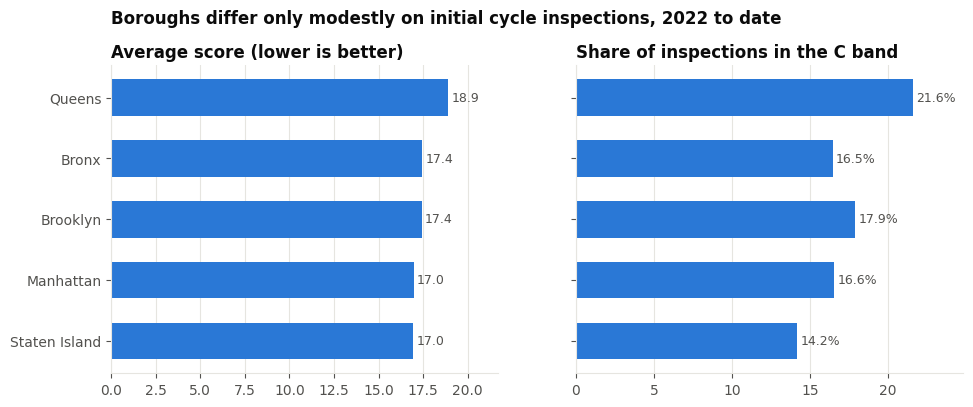

In [17]:
t = boro_tbl.sort_values("mean_score", ascending=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
axes[0].barh(t.index, t["mean_score"], color=BLUE, height=0.6)
axes[1].barh(t.index, t["pct_C"], color=BLUE, height=0.6)
for ax, col, fmt in [(axes[0], "mean_score", "{:.1f}"), (axes[1], "pct_C", "{:.1f}%")]:
    for i, val in enumerate(t[col]):
        ax.text(val + t[col].max() * 0.01, i, fmt.format(val), va="center", fontsize=9, color=INK2)
    ax.grid(axis="y", visible=False); ax.set_xlim(0, t[col].max() * 1.15)
axes[0].set_title("Average score (lower is better)")
axes[1].set_title("Share of inspections in the C band")
fig.suptitle("Boroughs differ only modestly on initial cycle inspections, 2022 to date", x=0.125, ha="left", fontsize=12, fontweight="bold", y=1.02)
save("03_borough_comparison")

## 5. Q2: Cuisine types
Only cuisines with at least 200 initial cycle inspections, so averages are not driven by a handful of restaurants.

In [36]:
cu = cyc_init.dropna(subset=["cuisine"]).groupby("cuisine")["score"].agg(
    n="size", mean_score="mean", median_score="median", pct_C=lambda s: (s >= 28).mean() * 100)
cu = cu[cu["n"] >= 200].sort_values("mean_score", ascending=False)
overall = cyc_init["score"].mean()
print(f"{len(cu)} cuisines with n >= 200 | overall mean score {overall:.1f}")
print("Highest:"); display(cu.head(10))
print("Lowest:"); display(cu.tail(10))

34 cuisines with n >= 200 | overall mean score 17.6
Highest:


,n,mean_score,median_score,pct_C
cuisine,,,,
Indian,449,24.78,21.00,32.96
Thai,522,23.19,21.00,31.23
Caribbean,1403,22.68,18.00,28.65
Asian/Asian Fusion,623,22.49,19.00,29.53
Spanish,722,21.59,18.00,26.32
Latin American,1990,21.36,17.00,27.34
Chinese,3550,20.99,16.00,25.30
Korean,583,20.42,13.00,24.36
Greek,236,20.13,13.50,26.27


Lowest:


,n,mean_score,median_score,pct_C
cuisine,,,,
American,8217,16.10,12.00,14.82
"Juice, Smoothies, Fruit Salads",906,15.60,12.00,13.36
Sandwiches,988,15.30,12.00,12.25
Frozen Desserts,596,14.39,12.00,10.91
Coffee/Tea,4114,13.94,11.00,10.21
Tex-Mex,700,13.46,11.00,10.86
Salads,252,13.20,11.00,10.32
Other,242,12.97,11.00,9.09
Hamburgers,1133,11.86,10.00,6.35


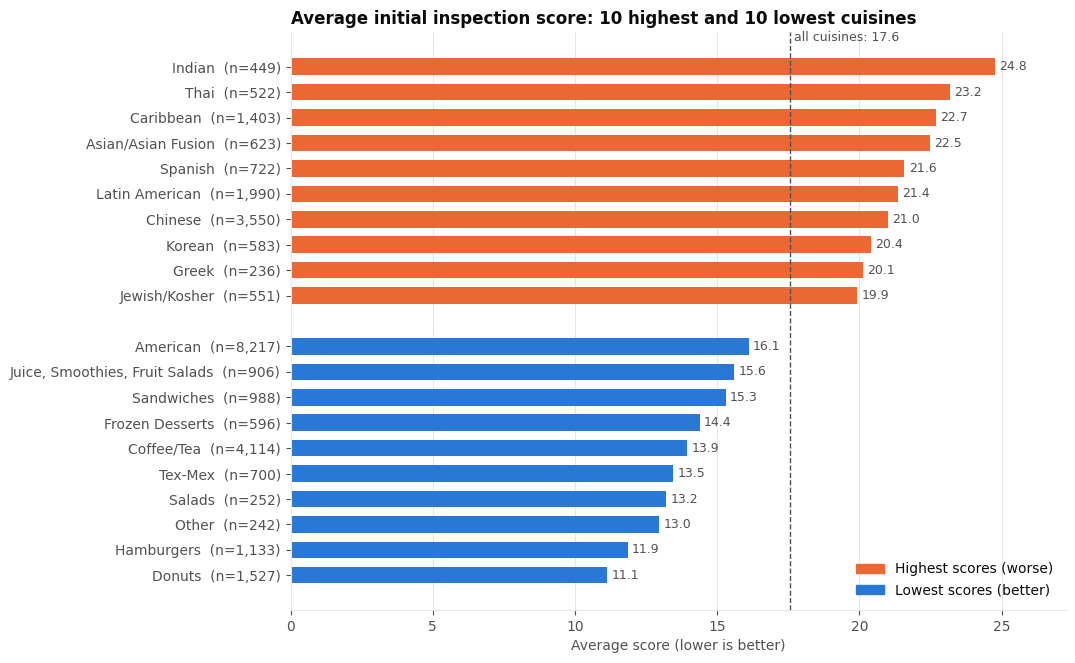

In [19]:
top, bot = cu.head(10), cu.tail(10)
plot = pd.concat([top, bot])
labels = [f"{c}  (n={int(n):,})" for c, n in zip(plot.index, plot["n"])]
colors = [ORANGE] * len(top) + [BLUE] * len(bot)
ypos = list(range(len(top))) + [len(top) + 1 + i for i in range(len(bot))]

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.barh(ypos, plot["mean_score"], color=colors, height=0.65)
for y, val in zip(ypos, plot["mean_score"]):
    ax.text(val + 0.15, y, f"{val:.1f}", va="center", fontsize=9, color=INK2)
ax.set_yticks(ypos); ax.set_yticklabels(labels); ax.invert_yaxis()
ax.axvline(overall, color=INK2, linestyle="--", linewidth=1)
ax.text(overall + 0.15, -0.9, f"all cuisines: {overall:.1f}", fontsize=9, color=INK2, va="bottom")
ax.set_xlim(0, plot["mean_score"].max() * 1.1)
ax.grid(axis="y", visible=False)
ax.set_title("Average initial inspection score: 10 highest and 10 lowest cuisines")
ax.set_xlabel("Average score (lower is better)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=ORANGE, label="Highest scores (worse)"), Patch(color=BLUE, label="Lowest scores (better)")], frameon=False, loc="lower right")
save("04_cuisine_scores")

## 6. Q3: Violations
Counted per inspection (not per row), over all inspections since 2022.

In [37]:
vi = v[v["inspection_date"] >= "2022-01-01"]
vi = vi[vi["violation_code"].notna()]
n_insp = recent.shape[0]

vc = vi.groupby("violation_code").agg(
    inspections=("inspection_id", "nunique"),
    description=("violation_description", "first"),
    critical_share=("is_critical", "mean"))
vc["prevalence_pct"] = vc["inspections"] / n_insp * 100
vc["is_critical"] = vc["critical_share"] > 0.5
vc = vc.sort_values("inspections", ascending=False)
print("Does a code ever switch between critical and not critical?", ((vc["critical_share"] > 0) & (vc["critical_share"] < 1)).sum(), "codes")
display(vc.head(15)[["inspections", "prevalence_pct", "is_critical", "description"]].assign(description=lambda d: d["description"].str.slice(0, 95)))

ins_crit = recent["n_critical"] >= 1
print(f"\nInspections with at least one critical violation: {ins_crit.mean()*100:.1f}%")
print(f"Average violations per inspection: {recent['n_violations'].mean():.1f} | critical: {recent['n_critical'].mean():.1f}")
print(f"Share of violation rows flagged critical: {vi['is_critical'].mean()*100:.1f}%")
print(f"Inspections with zero violations: {(recent['n_violations']==0).mean()*100:.1f}%")

Does a code ever switch between critical and not critical? 1 codes


,inspections,prevalence_pct,is_critical,description
violation_code,,,,
10F,40815,44.34,False,Non-food contact surface or equipment made of ...
08A,24802,26.95,False,Establishment is not free of harborage or cond...
06C,18932,20.57,True,"Food, supplies, or equipment not protected fro..."
02G,18826,20.45,True,Cold TCS food item held above 41 °F; smoked or...
10B,18819,20.45,False,Anti-siphonage or back-flow prevention device ...
06D,18346,19.93,True,"Food contact surface not properly washed, rins..."
02B,15334,16.66,True,Hot TCS food item not held at or above 140 °F.
04L,13554,14.73,True,Evidence of mice or live mice in establishment...
04N,11311,12.29,True,Filth flies or food/refuse/sewage associated w...



Inspections with at least one critical violation: 76.8%
Average violations per inspection: 3.1 | critical: 1.7
Share of violation rows flagged critical: 53.6%
Inspections with zero violations: 3.3%


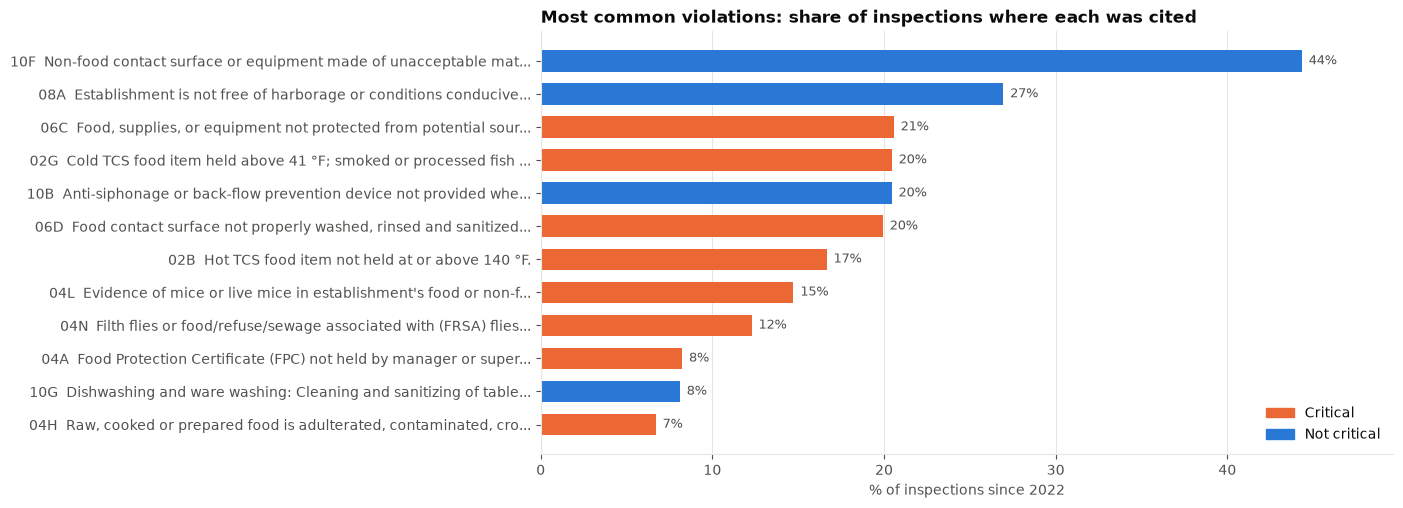

In [38]:
top15 = vc.head(12).iloc[::-1]
labels = [f"{c}  {d[:62]}{'...' if len(d) > 62 else ''}" for c, d in zip(top15.index, top15["description"])]
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(labels, top15["prevalence_pct"], color=[ORANGE if c else BLUE for c in top15["is_critical"]], height=0.65)
for i, val in enumerate(top15["prevalence_pct"]):
    ax.text(val + 0.4, i, f"{val:.0f}%", va="center", fontsize=9, color=INK2)
ax.set_xlim(0, top15["prevalence_pct"].max() * 1.12); ax.grid(axis="y", visible=False)
ax.set_title("Most common violations: share of inspections where each was cited")
ax.set_xlabel("% of inspections since 2022")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=ORANGE, label="Critical"), Patch(color=BLUE, label="Not critical")], frameon=False, loc="lower right")
save("05_top_violations")

## 7. Q4: Change over time
Monthly average score for initial cycle inspections since 2022. The current month is partial, so it is left out.

,inspections,mean_score,median_score,pct_A,pct_C
inspection_date,,,,,
2022,1094,16.06,12.00,60.69,15.90
2023,5979,16.07,12.00,63.87,15.02
2024,12520,17.65,13.00,59.59,17.77
2025,12746,17.75,13.00,60.34,18.40
2026,14069,18.08,13.00,58.55,19.15


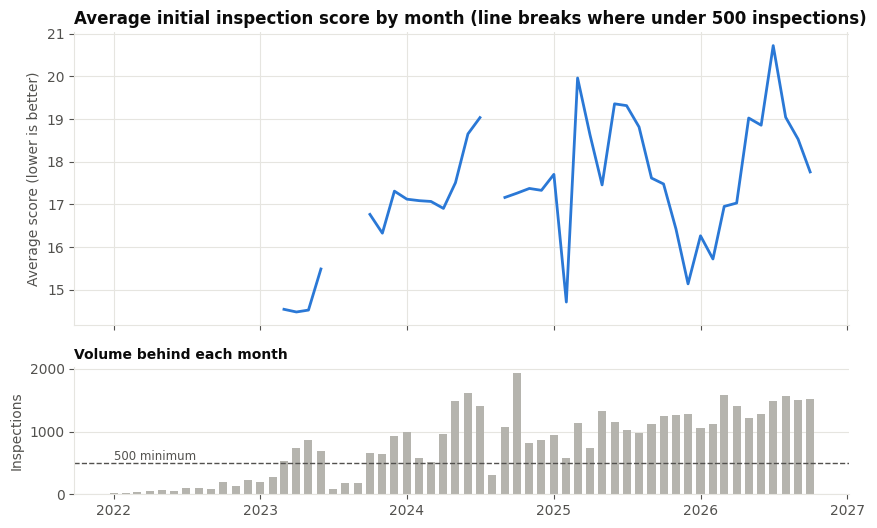

Months plotted: 40 of 58 | lowest Apr 2023 (14.5) | highest Jul 2026 (20.7)


In [22]:
mo = cyc_init.assign(month=cyc_init["inspection_date"].dt.to_period("M").dt.to_timestamp()).groupby("month")["score"].agg(
    n="size", mean_score="mean", pct_C=lambda s: (s >= 28).mean() * 100)
mo = mo.iloc[:-1]   # drop the partial final month
mo_plot = mo[mo["n"] >= 500]   # months with thin volume (early 2022) are too noisy to plot

yr = cyc_init.groupby(cyc_init["inspection_date"].dt.year)["score"].agg(
    inspections="size", mean_score="mean", median_score="median", pct_A=lambda s: (s <= 13).mean() * 100, pct_C=lambda s: (s >= 28).mean() * 100)
display(yr)

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
a1.plot(mo.index, mo["mean_score"].where(mo["n"] >= 500), color=BLUE, linewidth=2)   # NaN breaks the line where volume is thin
a1.set_ylabel("Average score (lower is better)"); a1.set_title("Average initial inspection score by month (line breaks where under 500 inspections)")
a2.bar(mo.index, mo["n"], width=20, color=GRAY); a2.axhline(500, color=INK2, linestyle="--", linewidth=1); a2.text(mo.index[0], 540, "500 minimum", fontsize=8.5, color=INK2)
a2.set_ylabel("Inspections"); a2.set_title("Volume behind each month", fontsize=10)
a2.grid(axis="x", visible=False)
save("06_score_over_time")
print(f"Months plotted: {len(mo_plot)} of {len(mo)} | lowest {mo_plot['mean_score'].idxmin():%b %Y} ({mo_plot['mean_score'].min():.1f}) | highest {mo_plot['mean_score'].idxmax():%b %Y} ({mo_plot['mean_score'].max():.1f})")

## 8. Q5: Do poorly scored restaurants improve on re-inspection?
For each initial cycle inspection since 2022 that scored 14 or more (B or C range), find that restaurant's *next* cycle inspection. If it is a re-inspection within 180 days, treat it as the follow-up.

In [23]:
cyc = insp[insp["inspection_type"].isin([INIT, REINSP]) & insp["score"].notna()].sort_values(["camis", "inspection_date", "inspection_type"]).copy()
g = cyc.groupby("camis")
cyc["next_type"] = g["inspection_type"].shift(-1)
cyc["next_date"] = g["inspection_date"].shift(-1)
cyc["next_score"] = g["score"].shift(-1)
cyc["days_to_next"] = (cyc["next_date"] - cyc["inspection_date"]).dt.days

failed = cyc[(cyc["inspection_type"] == INIT) & (cyc["score"] >= 14) & (cyc["inspection_date"] >= "2022-01-01")].copy()
failed["band"] = np.where(failed["score"] >= 28, "C (28+)", "B (14-27)")
failed["followed_up"] = (failed["next_type"] == REINSP) & (failed["days_to_next"] <= 180)
print("Days to re-inspection (matched):"); print(failed.loc[failed["followed_up"], "days_to_next"].describe())

pairs = failed[failed["followed_up"]].copy()
pairs["change"] = pairs["next_score"] - pairs["score"]
pairs["after_band"] = pd.cut(pairs["next_score"], [-1, 13, 27, np.inf], labels=["A", "B", "C"])

res = failed.groupby("band").agg(poor_initial_inspections=("score", "size"), with_reinspection=("followed_up", "sum"))
res["pct_with_reinspection"] = res["with_reinspection"] / res["poor_initial_inspections"] * 100
res = res.join(pairs.groupby("band").agg(
    mean_initial=("score", "mean"), mean_reinspection=("next_score", "mean"), mean_change=("change", "mean"),
    pct_improved=("change", lambda s: (s < 0).mean() * 100)))
res = res.join(pairs.groupby("band")["after_band"].value_counts(normalize=True).unstack().mul(100).add_prefix("pct_after_"))
display(res)
print(f"Overall: {len(pairs):,} follow-ups | {pairs['change'].lt(0).mean()*100:.1f}% improved | mean change {pairs['change'].mean():.1f} points | {pairs['after_band'].eq('A').mean()*100:.1f}% reached the A band")

Days to re-inspection (matched):
count   9,054.00
mean       80.83
std        46.73
min         2.00
25%        42.00
50%        70.00
75%       117.00
max       180.00
Name: days_to_next, dtype: float64


,poor_initial_inspections,with_reinspection,pct_with_reinspection,mean_initial,mean_reinspection,mean_change,pct_improved,pct_after_A,pct_after_B,pct_after_C
band,,,,,,,,,,
B (14-27),10199,4664,45.73,21.42,15.64,-5.79,77.74,68.85,20.90,10.25
C (28+),8336,4390,52.66,40.29,18.75,-21.54,91.55,57.97,26.24,15.79


Overall: 9,054 follow-ups | 84.4% improved | mean change -13.4 points | 63.6% reached the A band


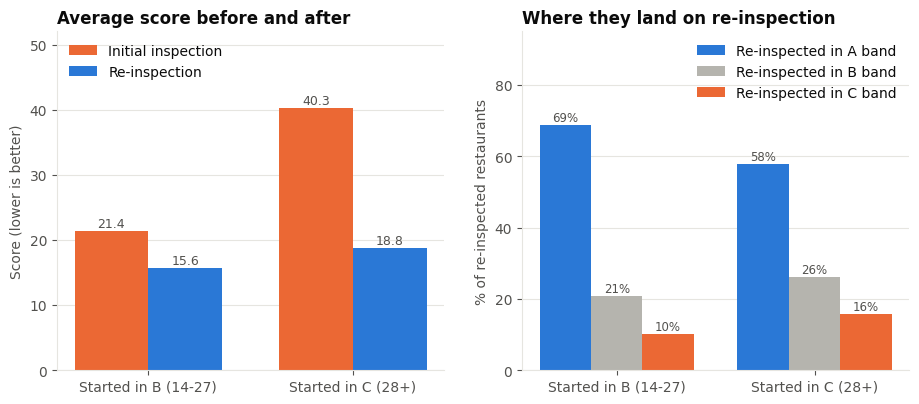

In [24]:
order = ["B (14-27)", "C (28+)"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.4))

x = np.arange(2); w = 0.36
b1 = a1.bar(x - w/2, res.loc[order, "mean_initial"], w, color=ORANGE, label="Initial inspection")
b2 = a1.bar(x + w/2, res.loc[order, "mean_reinspection"], w, color=BLUE, label="Re-inspection")
for bars in (b1, b2):
    for b in bars:
        a1.text(b.get_x() + b.get_width()/2, b.get_height() + 0.6, f"{b.get_height():.1f}", ha="center", fontsize=9, color=INK2)
a1.set_xticks(x); a1.set_xticklabels([f"Started in {o}" for o in order]); a1.grid(axis="x", visible=False)
a1.set_title("Average score before and after"); a1.set_ylabel("Score (lower is better)"); a1.set_ylim(0, 52); a1.legend(frameon=False, loc="upper left")

cols = {"A": BLUE, "B": GRAY, "C": ORANGE}
for j, band in enumerate(["A", "B", "C"]):
    vals = res.loc[order, f"pct_after_{band}"].fillna(0)
    bars = a2.bar(x + (j - 1) * 0.26, vals, 0.26, color=cols[band], label=f"Re-inspected in {band} band")
    for b in bars:
        a2.text(b.get_x() + b.get_width()/2, b.get_height() + 1, f"{b.get_height():.0f}%", ha="center", fontsize=8.5, color=INK2)
a2.set_xticks(x); a2.set_xticklabels([f"Started in {o}" for o in order]); a2.grid(axis="x", visible=False)
a2.set_title("Where they land on re-inspection"); a2.set_ylabel("% of re-inspected restaurants"); a2.set_ylim(0, 95); a2.legend(frameon=False, loc="upper right")
save("07_reinspection_improvement")

**Caution on Q5.** Restaurants are re-inspected *after* being told what to fix, so some improvement is expected, and extreme scores also tend to drift back toward the average. This shows that scores recover, not that re-inspection causes it. Restaurants without a matched re-inspection (closed, still pending, or inspected outside 180 days) are not in the follow-up numbers.

## 9. Save outputs

In [25]:
out_viol = "data/clean/restaurant_inspections_clean.csv"
out_insp = "data/clean/inspections_one_row_per_inspection.csv"
df.to_csv(out_viol, index=False)
insp.to_csv(out_insp, index=False)
log_df = pd.DataFrame(log)
log_df.to_csv("data/clean/cleaning_log.csv", index=False)

pd.set_option("display.max_colwidth", 90)
display(log_df)
print(f"\nSaved: {out_viol} ({len(df):,} rows), {out_insp} ({len(insp):,} rows), cleaning_log.csv, 7 charts in images/")
print("Raw rows:", len(df_raw), "-> clean rows:", len(df), "| never-inspected rows kept and flagged:", int(df['never_inspected'].sum()))

,problem,decision,reason,rows_affected
0,Column names have spaces and mixed case,Converted to snake_case,"Easier to reference, no hidden-whitespace bugs",27
1,Dates stored as text (MM/DD/YYYY),Parsed with an explicit format,"Needed for sorting, time series and date arithmetic",3
2,inspection_date = 1900-01-01,Set to NaT and flagged `never_inspected`,"Placeholder for restaurants not inspected yet (score, grade, violations all empty). Ke...",4024
3,Fully duplicated rows,"Dropped, kept first copy","Identical in all 27 columns, so they carry no extra information",225
4,boro = '0',Set to missing,Not a real borough; excluded from borough comparisons only,298
5,"ZIP codes outside NYC (NJ, Long Island) or invalid (69361)",Set to missing; stored as text,"ZIP is an identifier, not a number",129
6,Latitude/longitude of 0 (outside NYC),Set to missing,Would plot in the Atlantic Ocean,3046
7,Extra/repeated spaces in text fields (e.g. 'EAST 92 STREET'),Trimmed and collapsed to single spaces,Same street must not appear under two spellings,39386
8,Cuisine 'Not Listed/Not Applicable',Set to missing,"It is a placeholder, not a cuisine",56
9,"GRADE mixes letters (A/B/C) with status codes (N, Z, P) and is empty for ~half the rows",Kept raw `grade`; added `letter_grade` (A/B/C only). Analysis uses SCORE bands instead,Grades are only issued for some inspection types; the numeric score exists for far mor...,166203



Saved: data/clean/restaurant_inspections_clean.csv (294,475 rows), data/clean/inspections_one_row_per_inspection.csv (92,741 rows), cleaning_log.csv, 7 charts in images/
Raw rows: 294700 -> clean rows: 294475 | never-inspected rows kept and flagged: 4024


## 10. Findings

**Scope:** 92,741 inspections of 27,446 restaurants. Analyses use inspections since 2022 (92,045), and the like-for-like comparisons use the 46,408 initial cycle inspections that carry a score.

**Q1: Boroughs.** Differences are small. Average initial scores run from about 17.0 (Staten Island, Manhattan) to 18.9 (Queens), a gap of under 2 points. Queens also has the largest share in the C band (21.6%, versus 14.2% in Staten Island and about 16.5% in Manhattan and the Bronx). The difference is statistically significant (Kruskal-Wallis, p < 0.001), but with this many inspections almost any gap is, so the practical difference is modest. Closure rates (share of inspections ending in a closure) are highest in Brooklyn (2.6%) and Queens (2.4%) and lowest in Staten Island (1.1%).

**Q2: Cuisines.** Among 34 cuisines with 200+ initial inspections, Indian (24.8), Thai (23.2) and Caribbean (22.7) have the highest average scores, against 17.6 overall. Donuts (11.1), Hamburgers (11.9) and the "Other" group (13.0) have the lowest, with Coffee/Tea (13.9) also well below average. Cuisines built around simple counter service score better than full-menu, cook-to-order kitchens, but this analysis does not test why. Cuisine is also not adjusted for borough or restaurant size.

**Q3: Violations.** 76.8% of inspections cite at least one critical violation, and the average inspection has 3.1 violations, 1.7 of them critical. Only 3.3% of inspections record zero violations. The most common violation is a non-critical one, 10F (non-food contact surfaces made of unacceptable material), cited in 44% of inspections. The most common critical ones are 06C (food not protected from contamination, 21%), 02G (cold food held above 41 °F, 20%) and 06D (food contact surfaces not sanitized, 20%). Evidence of mice (04L) appears in 14.7% of inspections.

**Q4: Over time.** Average initial scores drifted up slightly, from 17.65 in 2024 to 17.75 in 2025 and 18.08 in 2026 so far, and the share in the C band rose from 15.0% (2023) to 19.2% (2026). 2022 and 2023 are thin (1,094 and 5,979 initial inspections) and may reflect which restaurants have older records, so the cleanest comparison is 2024 onward: a mild upward drift of about 0.4 points, not a clear trend.

**Q5: Re-inspection.** Of 18,535 poor initial inspections (score 14+), 49% had a cycle re-inspection within 180 days (median 70 days). Among those, 84% improved and scores fell by 13.4 points on average. Restaurants that started in the C band fell from 40.3 to 18.8 (91.6% improved), and those that started in the B band fell from 21.4 to 15.6 (77.7% improved). 63.6% of all re-inspected restaurants reached the A band. This is descriptive: a re-inspection happens after the restaurant has fixed cited problems, and unusually bad scores tend to be followed by better ones anyway.

## 11. Limitations
- The file is a snapshot (downloaded 2026-11-11). Years before 2022 hold only a few hundred inspections each, so they are excluded from comparisons.
- Scores are only available for some inspection types. Administrative inspections never have a score, and letter grades exist for roughly half the rows, so score bands are used instead of grades.
- Letter grades and score bands disagree on 0.3% of graded rows (417); these were left as published.
- 103 restaurants with borough `0` are excluded from borough comparisons, and 129 rows with non-NYC ZIP codes have their ZIP set to missing.
- Cuisine labels overlap (for example "Hotdogs" and "Hotdogs/Pretzels", "Soups" and "Soups/Salads/Sandwiches") and were not merged.
- Findings are observational. They describe patterns in the data, not causes.